# Introducción
La pregunta de investigación es la siguiente: ¿los marcadores fisiológicos pueden predecir la aparición posterior de fatiga cognifiva subjetiva antes de que esta se manifieste conscientemente? Por ejemplo, teniendo dos tismpos T0 y T1, con los marcadores fisiológicos, ¿pueden los marcadores fisiológicos en T0 predecir la aparición de fatiga cognitiva subjetiva en T1, antes de que dicha fatiga sea conscientemente reportada por el individuo?

# Metodología
Este es un estudio de predicción temporal de la fatiga a partir de marcadores fisiológicos, usando estadística como método principal y ML como análisis complementario
Utilizaremos modelos estadísticos logitudinales, como:
- Linear Mixed Effects Model
- Generalized Mixed Effects Model
- Elastic Net or Lasso (a debatir cuál)

Añadir otra variable: El cambio entre fatigas (T1 - T0)



In [1]:
from pathlib import Path
import pandas as pd

DATA_DIR = Path("data")

csv_files = sorted(DATA_DIR.glob("*.csv"))

print(f"Datasets encontrados: {len(csv_files)}\n")

datasets = {}

for file in csv_files:
    df = pd.read_csv(file)
    datasets[file.stem] = df

    print("=" * 80)
    print(file.name)
    print(f"Shape: {df.shape}")
    print(f"Columnas ({len(df.columns)}):")
    print(df.columns.tolist())
    print()

Datasets encontrados: 6

MRSFATIGUE_choice_bias_parameter_zenodo.csv
Shape: (2400, 7)
Columnas (7):
['condition', 'domain', 'subject_id', 'session', 'model', 'parameter_name', 'parameter_value']

MRSFATIGUE_MRS_DWS_session_ADC_log_Glu_Gln_lin_zenodo.csv
Shape: (229, 9)
Columnas (9):
['subject_id', 'condition', 'session', 'ROI', 'WCONC_corr', 'p_shots_kept', 'SN', 'linewidth', 'ADC_log_Glu_Gln_lin']

MRSFATIGUE_MRS_semiLaser_session_ratio_Glu_tCr_zenodo.csv
Shape: (194, 10)
Columnas (10):
['subject_id', 'Linewidth', 'SNR', 'WCONC_corr', 'ROI', 'session', 'condition', 'distance', 'rotation', 'Glu_tCr']

MRSFATIGUE_ntask_session_zenodo.csv
Shape: (326472, 9)
Columnas (9):
['condition', 'task', 'subject_id', 'session', 'block', 'trial', 'rule_switch', 'performance', 'response_time']

MRSFATIGUE_pupil_choice_session_zenodo.csv
Shape: (37208, 392)
Columnas (392):
['subject_id', 'condition', 'session', 'response_time', 'choiceSS', 'choiceSS_before', 'domain', 'effective_dimensions', 'ITI_befo

### Identificar posibles key variables

In [2]:
for name, df in datasets.items():
    print("\n", "=" * 80)
    print(name)

    possible_ids = [
        c for c in df.columns
        if any(
            key in c.lower()
            for key in [
                "subject",
                "participant",
                "session",
                "trial",
                "condition",
                "id"
            ]
        )
    ]

    print("Posibles identificadores:")
    print(possible_ids)


MRSFATIGUE_choice_bias_parameter_zenodo
Posibles identificadores:
['condition', 'subject_id', 'session']

MRSFATIGUE_MRS_DWS_session_ADC_log_Glu_Gln_lin_zenodo
Posibles identificadores:
['subject_id', 'condition', 'session', 'linewidth']

MRSFATIGUE_MRS_semiLaser_session_ratio_Glu_tCr_zenodo
Posibles identificadores:
['subject_id', 'Linewidth', 'session', 'condition']

MRSFATIGUE_ntask_session_zenodo
Posibles identificadores:
['condition', 'subject_id', 'session', 'trial']

MRSFATIGUE_pupil_choice_session_zenodo
Posibles identificadores:
['subject_id', 'condition', 'session']

MRSFATIGUE_ratings_session_zenodo
Posibles identificadores:
['condition', 'subject_id', 'session']


In [3]:
ratings = datasets["MRSFATIGUE_ratings_session_zenodo"].copy()

print("Preguntas disponibles:\n")

for q in ratings["question"].dropna().unique():
    print(repr(q))

print("\nNúmero de respuestas por pregunta:")
print(
    ratings.groupby("question")
           .agg(
               n=("rating", "count"),
               subjects=("subject_id", "nunique")
           )
)

print(
    ratings.groupby("question")["rating"]
    .agg(["count", "mean", "std", "min", "median", "max"])
)

print(
    ratings.groupby("question")["rating"]
    .agg(["count", "mean", "std", "min", "median", "max"])
)

Preguntas disponibles:

'Fatigue'
'Stress'
'Hunger'

Número de respuestas por pregunta:
            n  subjects
question               
Fatigue   207        40
Hunger    207        40
Stress    207        40
          count       mean        std       min     median         max
question                                                              
Fatigue     207  56.233133  27.036328  1.730104  57.785467  100.000000
Hunger      207  29.939054  27.051148  0.346021  22.837370  100.000000
Stress      207  25.601708  23.218671  0.346021  18.685121   97.927461
          count       mean        std       min     median         max
question                                                              
Fatigue     207  56.233133  27.036328  1.730104  57.785467  100.000000
Hunger      207  29.939054  27.051148  0.346021  22.837370  100.000000
Stress      207  25.601708  23.218671  0.346021  18.685121   97.927461


### Y robusta

In [4]:
ratings = datasets[
    "MRSFATIGUE_ratings_session_zenodo"
].copy()

fatigue = (
    ratings[ratings["question"] == "Fatigue"]
    [["subject_id", "condition", "session", "rating"]]
    .rename(columns={"rating": "fatigue"})
    .sort_values(["subject_id", "session"])
    .reset_index(drop=True)
)

display(fatigue.head(15))

print("Shape:", fatigue.shape)
print("\nSesiones:")
print(fatigue["session"].value_counts().sort_index())

,subject_id,condition,session,fatigue
0,1,hard,0,14.532872
1,1,hard,2,79.930796
2,1,hard,2,31.487889
3,1,hard,4,82.006920
4,1,hard,5,93.079585
5,2,hard,0,2.590674
6,2,hard,3,36.787565
7,2,hard,5,66.321244
8,3,hard,0,62.694301
9,3,hard,3,72.538860


Shape: (207, 4)

Sesiones:
session
0    40
1    14
2    37
3    40
4    36
5    40
Name: count, dtype: int64


### Creamos t-> t+1

In [5]:
fatigue["fatigue_future"] = (
    fatigue.groupby("subject_id")["fatigue"]
           .shift(-1)
)

fatigue["session_future"] = (
    fatigue.groupby("subject_id")["session"]
           .shift(-1)
)

fatigue["delta_fatigue"] = (
    fatigue["fatigue_future"]
    - fatigue["fatigue"]
)

fatigue_long = fatigue.dropna(
    subset=["fatigue_future"]
).copy()

display(fatigue_long.head(20))

,subject_id,condition,session,fatigue,fatigue_future,session_future,delta_fatigue
0,1,hard,0,14.532872,79.930796,2.0,65.397924
1,1,hard,2,79.930796,31.487889,2.0,-48.442907
2,1,hard,2,31.487889,82.006920,4.0,50.519031
3,1,hard,4,82.006920,93.079585,5.0,11.072664
5,2,hard,0,2.590674,36.787565,3.0,34.196891
6,2,hard,3,36.787565,66.321244,5.0,29.533679
8,3,hard,0,62.694301,72.538860,3.0,9.844560
9,3,hard,3,72.538860,89.119171,5.0,16.580311
11,4,hard,0,26.424870,51.295337,0.0,24.870466
12,4,hard,0,51.295337,55.958549,3.0,4.663212


In [6]:
transitions = (
    fatigue_long
    .groupby(["session", "session_future"])
    .size()
    .rename("n")
    .reset_index()
)

display(transitions)

,session,session_future,n
0,0,0.0,1
1,0,1.0,13
2,0,2.0,21
3,0,3.0,5
4,1,1.0,1
5,1,2.0,13
6,2,2.0,2
7,2,3.0,34
8,2,4.0,1
9,3,3.0,1


In [7]:
Y_future = fatigue_long["fatigue_future"]
Y_delta  = fatigue_long["delta_fatigue"]

In [8]:
ratings_wide = (
    ratings
    .pivot_table(
        index=["subject_id", "condition", "session"],
        columns="question",
        values="rating",
        aggfunc="first"
    )
    .reset_index()
    .rename(columns={
        "Fatigue": "fatigue",
        "Stress": "stress",
        "Hunger": "hunger"
    })
)

ratings_wide.columns.name = None

display(ratings_wide.head())

,subject_id,condition,session,fatigue,hunger,stress
0,1,hard,0,14.532872,20.415225,34.948097
1,1,hard,2,79.930796,65.743945,66.435986
2,1,hard,4,82.006920,61.591696,71.972318
3,1,hard,5,93.079585,34.602076,46.366782
4,2,hard,0,2.590674,0.518135,10.880829


### Convertir n tasks de trial -> subject x session

In [9]:
MRSFATIGUE_ntask_session_zenodo = datasets["MRSFATIGUE_ntask_session_zenodo"].copy()

display(MRSFATIGUE_ntask_session_zenodo.head())

print(MRSFATIGUE_ntask_session_zenodo.dtypes)
print("\MRSFATIGUE_ntask_session_zenodos:")
print(MRSFATIGUE_ntask_session_zenodo["task"].value_counts(dropna=False))

print("\nPerformance:")
print(MRSFATIGUE_ntask_session_zenodo["performance"].value_counts(dropna=False))

<>:6: SyntaxWarning: invalid escape sequence '\M'
<>:6: SyntaxWarning: invalid escape sequence '\M'
C:\Users\meyli\AppData\Local\Temp\ipykernel_33056\1357523749.py:6: SyntaxWarning: invalid escape sequence '\M'
  print("\MRSFATIGUE_ntask_session_zenodos:")


,condition,task,subject_id,session,block,trial,rule_switch,performance,response_time
0,hard,nswitch,1,1,33,1,0.0,1.0,0.653528
1,hard,nswitch,1,1,33,2,0.0,0.0,0.441274
2,hard,nswitch,1,1,33,3,0.0,0.0,0.264650
3,hard,nswitch,1,1,33,4,1.0,0.0,0.541202
4,hard,nswitch,1,1,33,5,0.0,0.0,0.474042


condition            str
task                 str
subject_id         int64
session            int64
block              int64
trial              int64
rule_switch      float64
performance      float64
response_time    float64
dtype: object
\MRSFATIGUE_ntask_session_zenodos:
task
nswitch    163896
nback      162576
Name: count, dtype: int64

Performance:
performance
1.0    278243
0.0     46065
NaN      2164
Name: count, dtype: int64


#### Construcción de features conductuales por sujeto y sesión

In [10]:
import numpy as np
import pandas as pd

MRSFATIGUE_ntask_session_zenodo_session = (
    MRSFATIGUE_ntask_session_zenodo
    .groupby(["subject_id", "condition", "session"])
    .agg(
        n_trials=("trial", "size"),

        # Rendimiento
        accuracy=("performance", "mean"),

        # Tiempo de respuesta
        mean_rt=("response_time", "mean"),
        median_rt=("response_time", "median"),
        rt_std=("response_time", "std"),

        # Task switching
        switch_fraction=("rule_switch", "mean")
    )
    .reset_index()
)

display(MRSFATIGUE_ntask_session_zenodo_session.head())

print("Shape:", MRSFATIGUE_ntask_session_zenodo_session.shape)
print("Sujetos:", MRSFATIGUE_ntask_session_zenodo_session["subject_id"].nunique())
print("\nSesiones:")
print(MRSFATIGUE_ntask_session_zenodo_session["session"].value_counts().sort_index())

,subject_id,condition,session,n_trials,accuracy,mean_rt,median_rt,rt_std,switch_fraction
0,1,hard,1,1752,0.726598,0.544624,0.548653,0.127825,0.5
1,1,hard,2,2040,0.534804,0.540636,0.553485,0.149004,0.5
2,1,hard,3,1632,0.672794,0.547459,0.560099,0.151890,0.5
3,1,hard,4,1584,0.645202,0.534747,0.546037,0.146042,0.5
4,1,hard,5,1728,0.646412,0.531357,0.543077,0.154741,0.5


Shape: (200, 9)
Sujetos: 40

Sesiones:
session
1    40
2    40
3    40
4    40
5    40
Name: count, dtype: int64


In [11]:
MRSFATIGUE_ntask_session_zenodo_sorted = MRSFATIGUE_ntask_session_zenodo.sort_values(
    ["subject_id", "session", "trial"]
).copy()

MRSFATIGUE_ntask_session_zenodo_sorted["trial_fraction"] = (
    MRSFATIGUE_ntask_session_zenodo_sorted.groupby(
        ["subject_id", "session"]
    ).cumcount()
    /
    MRSFATIGUE_ntask_session_zenodo_sorted.groupby(
        ["subject_id", "session"]
    )["trial"].transform("size")
)

early = (
    MRSFATIGUE_ntask_session_zenodo_sorted[
        MRSFATIGUE_ntask_session_zenodo_sorted["trial_fraction"] < 0.25
    ]
    .groupby(["subject_id", "condition", "session"])
    .agg(
        early_accuracy=("performance", "mean"),
        early_rt=("response_time", "median")
    )
    .reset_index()
)

late = (
    MRSFATIGUE_ntask_session_zenodo_sorted[
        MRSFATIGUE_ntask_session_zenodo_sorted["trial_fraction"] >= 0.75
    ]
    .groupby(["subject_id", "condition", "session"])
    .agg(
        late_accuracy=("performance", "mean"),
        late_rt=("response_time", "median")
    )
    .reset_index()
)

MRSFATIGUE_ntask_session_zenodo_session = (
    MRSFATIGUE_ntask_session_zenodo_session
    .merge(
        early,
        on=["subject_id", "condition", "session"],
        how="left"
    )
    .merge(
        late,
        on=["subject_id", "condition", "session"],
        how="left"
    )
)

MRSFATIGUE_ntask_session_zenodo_session["within_session_rt_change"] = (
    MRSFATIGUE_ntask_session_zenodo_session["late_rt"]
    - MRSFATIGUE_ntask_session_zenodo_session["early_rt"]
)

MRSFATIGUE_ntask_session_zenodo_session["within_session_accuracy_change"] = (
    MRSFATIGUE_ntask_session_zenodo_session["late_accuracy"]
    - MRSFATIGUE_ntask_session_zenodo_session["early_accuracy"]
)

display(MRSFATIGUE_ntask_session_zenodo_session.head())

,subject_id,condition,session,n_trials,accuracy,mean_rt,median_rt,rt_std,switch_fraction,early_accuracy,early_rt,late_accuracy,late_rt,within_session_rt_change,within_session_accuracy_change
0,1,hard,1,1752,0.726598,0.544624,0.548653,0.127825,0.5,0.684932,0.540679,0.694064,0.564722,0.024043,0.009132
1,1,hard,2,2040,0.534804,0.540636,0.553485,0.149004,0.5,0.447059,0.536057,0.547059,0.558487,0.022431,0.100000
2,1,hard,3,1632,0.672794,0.547459,0.560099,0.151890,0.5,0.644608,0.555563,0.607843,0.577870,0.022307,-0.036765
3,1,hard,4,1584,0.645202,0.534747,0.546037,0.146042,0.5,0.573232,0.533376,0.578283,0.560052,0.026676,0.005051
4,1,hard,5,1728,0.646412,0.531357,0.543077,0.154741,0.5,0.587963,0.554993,0.599537,0.557371,0.002378,0.011574


### Y temporal conservadora

In [12]:
fatigue_raw = (
    ratings[ratings["question"] == "Fatigue"]
    [["subject_id", "condition", "session", "rating"]]
    .rename(columns={"rating": "fatigue"})
    .copy()
)

# Número de ratings por sujeto × condición × sesión
fatigue_raw["n_in_session"] = (
    fatigue_raw
    .groupby(["subject_id", "condition", "session"])["fatigue"]
    .transform("size")
)

# Dataset principal: sólo momentos temporalmente inequívocos
fatigue_clean = (
    fatigue_raw[fatigue_raw["n_in_session"] == 1]
    .drop(columns="n_in_session")
    .sort_values(["subject_id", "condition", "session"])
    .reset_index(drop=True)
)

print("Ratings originales:", len(fatigue_raw))
print("Ratings utilizables:", len(fatigue_clean))
print("Ratings ambiguos preservados aparte:",
      len(fatigue_raw) - len(fatigue_clean))

assert not fatigue_clean.duplicated(
    ["subject_id", "condition", "session"]
).any()

Ratings originales: 207
Ratings utilizables: 195
Ratings ambiguos preservados aparte: 12


### Unir comportamiento en t con fatiga en t+1

In [13]:
fatigue_clean["fatigue_future"] = (
    fatigue_clean
    .groupby(["subject_id", "condition"])["fatigue"]
    .shift(-1)
)

fatigue_clean["session_future"] = (
    fatigue_clean
    .groupby(["subject_id", "condition"])["session"]
    .shift(-1)
)

# Distancia temporal
fatigue_clean["session_gap"] = (
    fatigue_clean["session_future"]
    - fatigue_clean["session"]
)

# Sólo t -> t+1
fatigue_long = (
    fatigue_clean[
        fatigue_clean["session_gap"] == 1
    ]
    .copy()
)

fatigue_long["delta_fatigue"] = (
    fatigue_long["fatigue_future"]
    - fatigue_long["fatigue"]
)

In [14]:
print("Transiciones válidas:", len(fatigue_long))
print("Sujetos:", fatigue_long["subject_id"].nunique())

display(
    fatigue_long
    .groupby(["session", "session_future"])
    .size()
    .rename("n")
    .reset_index()
)

Transiciones válidas: 123
Sujetos: 34


,session,session_future,n
0,0,1.0,12
1,1,2.0,12
2,2,3.0,32
3,3,4.0,33
4,4,5.0,34


### merge con ntask

In [15]:
model_df = fatigue_long.merge(
    MRSFATIGUE_ntask_session_zenodo_session,
    on=["subject_id", "condition", "session"],
    how="left",
    validate="one_to_one",
    indicator=True
)

print(model_df["_merge"].value_counts())

model_df = model_df.drop(columns="_merge")

print("Shape final:", model_df.shape)

display(
    model_df[
        [
            "subject_id",
            "condition",
            "session",
            "fatigue",
            "accuracy",
            "median_rt",
            "fatigue_future",
            "delta_fatigue"
        ]
    ].head(20)
)

_merge
both          111
left_only      12
right_only      0
Name: count, dtype: int64
Shape final: (123, 20)


,subject_id,condition,session,fatigue,accuracy,median_rt,fatigue_future,delta_fatigue
0,1,hard,4,82.006920,0.645202,0.546037,93.079585,11.072664
1,5,hard,2,31.487889,0.811237,0.535696,50.519031,19.031142
2,5,hard,3,50.519031,0.721284,0.525474,55.363322,4.844291
3,5,hard,4,55.363322,0.654040,0.550748,84.429066,29.065744
4,8,hard,2,71.626298,0.928030,0.483788,88.235294,16.608997
5,8,hard,3,88.235294,0.933449,0.475659,67.474048,-20.761246
6,8,hard,4,67.474048,0.942551,0.488945,80.276817,12.802768
7,9,hard,2,47.058824,0.871843,0.482700,47.058824,0.000000
8,9,hard,3,47.058824,0.883838,0.475835,57.785467,10.726644
9,9,hard,4,57.785467,0.886364,0.511500,59.169550,1.384083


### Investigación de MRS

In [16]:
dws = datasets[
    "MRSFATIGUE_MRS_DWS_session_ADC_log_Glu_Gln_lin_zenodo"
].copy()

glu = datasets[
    "MRSFATIGUE_MRS_semiLaser_session_ratio_Glu_tCr_zenodo"
].copy()


print("=== DWS ===")
print("ROI:")
print(dws["ROI"].value_counts(dropna=False))

print("\nSesiones:")
print(dws["session"].value_counts(dropna=False).sort_index())

print("\nCondition:")
print(dws["condition"].value_counts(dropna=False))

print("\nADC missing:")
print(dws["ADC_log_Glu_Gln_lin"].isna().sum())


print("\n\n=== semiLASER ===")
print("ROI:")
print(glu["ROI"].value_counts(dropna=False))

print("\nSesiones:")
print(glu["session"].value_counts(dropna=False).sort_index())

print("\nCondition:")
print(glu["condition"].value_counts(dropna=False))

print("\nGlu_tCr missing:")
print(glu["Glu_tCr"].isna().sum())


print("=== DWS: filas por subject × session × ROI ===")

print(
    dws.groupby(
        ["subject_id", "condition", "session", "ROI"]
    )
    .size()
    .value_counts()
    .sort_index()
)


print("\n=== semiLASER: filas por subject × session × ROI ===")

print(
    glu.groupby(
        ["subject_id", "condition", "session", "ROI"]
    )
    .size()
    .value_counts()
    .sort_index()
)

=== DWS ===
ROI:
ROI
PFC    118
VC     111
Name: count, dtype: int64

Sesiones:
session
1    76
3    75
5    78
Name: count, dtype: int64

Condition:
condition
hard    137
easy     92
Name: count, dtype: int64

ADC missing:
0


=== semiLASER ===
ROI:
ROI
PFC    99
VC     95
Name: count, dtype: int64

Sesiones:
session
1    65
3    61
5    68
Name: count, dtype: int64

Condition:
condition
hard    118
easy     76
Name: count, dtype: int64

Glu_tCr missing:
0
=== DWS: filas por subject × session × ROI ===
1    229
Name: count, dtype: int64

=== semiLASER: filas por subject × session × ROI ===
1    194
Name: count, dtype: int64


In [17]:
dws_values = [
    "ADC_log_Glu_Gln_lin",
    "WCONC_corr",
    "p_shots_kept",
    "SN",
    "linewidth"
]

dws_wide = (
    dws
    .pivot(
        index=["subject_id", "condition", "session"],
        columns="ROI",
        values=dws_values
    )
)

# Aplanar nombres
dws_wide.columns = [
    f"DWS_{variable}_{roi}"
    for variable, roi in dws_wide.columns
]

dws_wide = dws_wide.reset_index()

display(dws_wide.head())
print("Shape DWS:", dws_wide.shape)

,subject_id,condition,session,DWS_ADC_log_Glu_Gln_lin_PFC,DWS_ADC_log_Glu_Gln_lin_VC,DWS_WCONC_corr_PFC,DWS_WCONC_corr_VC,DWS_p_shots_kept_PFC,DWS_p_shots_kept_VC,DWS_SN_PFC,DWS_SN_VC,DWS_linewidth_PFC,DWS_linewidth_VC
0,1,hard,1,NaN,-0.000161,NaN,38997.573803,NaN,0.732955,NaN,12.636364,NaN,4.571455
1,1,hard,3,-0.000131,-0.000251,38302.4027,38997.573803,0.718750,0.729167,19.400000,11.333333,3.919350,4.437000
2,1,hard,5,-0.000165,-0.000156,38302.4027,38997.573803,0.798611,0.778409,18.555556,13.545455,3.944000,6.476227
3,2,hard,1,-0.000128,-0.000129,38847.4339,39475.498285,0.864583,0.833333,19.000000,13.916667,3.635875,4.252125
4,2,hard,3,-0.000120,-0.000147,38847.4339,39359.170149,0.765625,0.793750,17.083333,15.700000,4.190500,4.067250


Shape DWS: (119, 13)


In [18]:
glu_values = [
    "Glu_tCr",
    "Linewidth",
    "SNR",
    "WCONC_corr",
    "distance",
    "rotation"
]

glu_wide = (
    glu
    .pivot(
        index=["subject_id", "condition", "session"],
        columns="ROI",
        values=glu_values
    )
)

glu_wide.columns = [
    f"MRS_{variable}_{roi}"
    for variable, roi in glu_wide.columns
]

glu_wide = glu_wide.reset_index()

display(glu_wide.head())
print("Shape semiLASER:", glu_wide.shape)

,subject_id,condition,session,MRS_Glu_tCr_PFC,MRS_Glu_tCr_VC,MRS_Linewidth_PFC,MRS_Linewidth_VC,MRS_SNR_PFC,MRS_SNR_VC,MRS_WCONC_corr_PFC,MRS_WCONC_corr_VC,MRS_distance_PFC,MRS_distance_VC,MRS_rotation_PFC,MRS_rotation_VC
0,1,hard,1,1.198457,NaN,4.428,NaN,64.0,NaN,38302.4027,NaN,0.628763,NaN,0.010381,NaN
1,1,hard,5,NaN,1.083321,NaN,4.428,NaN,58.0,NaN,38997.573803,NaN,1.191763,NaN,0.032864
2,2,hard,3,1.142647,1.091175,5.904,4.428,39.0,49.0,38847.4339,39359.170149,2.019547,0.530198,0.016582,0.003712
3,2,hard,5,NaN,1.073877,NaN,4.428,NaN,44.0,NaN,39591.826421,NaN,1.523531,NaN,0.013683
4,3,hard,1,1.408371,1.178118,5.904,4.428,36.0,59.0,40914.8472,39404.481923,0.228572,1.021905,0.024836,0.023978


Shape semiLASER: (111, 15)


In [19]:
model_full = model_df.merge(
    dws_wide,
    on=["subject_id", "condition", "session"],
    how="left",
    validate="one_to_one"
)

model_full = model_full.merge(
    glu_wide,
    on=["subject_id", "condition", "session"],
    how="left",
    validate="one_to_one"
)

print("Shape multimodal:", model_full.shape)

display(model_full.head())

Shape multimodal: (123, 42)


,subject_id,condition,session,fatigue,fatigue_future,session_future,session_gap,delta_fatigue,n_trials,accuracy,...,MRS_Linewidth_PFC,MRS_Linewidth_VC,MRS_SNR_PFC,MRS_SNR_VC,MRS_WCONC_corr_PFC,MRS_WCONC_corr_VC,MRS_distance_PFC,MRS_distance_VC,MRS_rotation_PFC,MRS_rotation_VC
0,1,hard,4,82.006920,93.079585,5.0,1.0,11.072664,1584.0,0.645202,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,5,hard,2,31.487889,50.519031,3.0,1.0,19.031142,1584.0,0.811237,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,5,hard,3,50.519031,55.363322,4.0,1.0,4.844291,1776.0,0.721284,...,4.428,NaN,64.0,NaN,38700.1744,NaN,0.351549,NaN,0.002416,NaN
3,5,hard,4,55.363322,84.429066,5.0,1.0,29.065744,1584.0,0.654040,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,8,hard,2,71.626298,88.235294,3.0,1.0,16.608997,1584.0,0.928030,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [20]:
availability = pd.DataFrame({
    "MRSFATIGUE_ntask_session_zenodo": model_full["accuracy"].notna(),
    "DWS_PFC": model_full["DWS_ADC_log_Glu_Gln_lin_PFC"].notna(),
    "DWS_VC": model_full["DWS_ADC_log_Glu_Gln_lin_VC"].notna(),
    "Glu_PFC": model_full["MRS_Glu_tCr_PFC"].notna(),
    "Glu_VC": model_full["MRS_Glu_tCr_VC"].notna()
})

print(availability.sum())

availability_by_session = (
    model_full
    .assign(
        has_MRSFATIGUE_ntask_session_zenodo=model_full["accuracy"].notna(),
        has_DWS_PFC=model_full["DWS_ADC_log_Glu_Gln_lin_PFC"].notna(),
        has_DWS_VC=model_full["DWS_ADC_log_Glu_Gln_lin_VC"].notna(),
        has_Glu_PFC=model_full["MRS_Glu_tCr_PFC"].notna(),
        has_Glu_VC=model_full["MRS_Glu_tCr_VC"].notna()
    )
    .groupby("session")[
        [
            "has_MRSFATIGUE_ntask_session_zenodo",
            "has_DWS_PFC",
            "has_DWS_VC",
            "has_Glu_PFC",
            "has_Glu_VC"
        ]
    ]
    .sum()
)

display(availability_by_session)

MRSFATIGUE_ntask_session_zenodo    111
DWS_PFC                             45
DWS_VC                              41
Glu_PFC                             36
Glu_VC                              36
dtype: int64


,has_MRSFATIGUE_ntask_session_zenodo,has_DWS_PFC,has_DWS_VC,has_Glu_PFC,has_Glu_VC
session,,,,,
0,0,0,0,0,0
1,12,12,11,9,11
2,32,0,0,0,0
3,33,33,30,27,25
4,34,0,0,0,0


### Modelo longitudinal base

In [21]:
import statsmodels.formula.api as smf

baseline_df = (
    model_full[
        [
            "subject_id",
            "condition",
            "session",
            "fatigue",
            "fatigue_future"
        ]
    ]
    .dropna()
    .copy()
)

print("N:", len(baseline_df))
print("Sujetos:", baseline_df["subject_id"].nunique())

model_1 = smf.mixedlm(
    "fatigue_future ~ fatigue + session + C(condition)",
    data=baseline_df,
    groups=baseline_df["subject_id"]
)

result_1 = model_1.fit(
    reml=False,
    method="powell"
)

print(result_1.summary())

clustered_model = smf.ols(
    "fatigue_future ~ fatigue + session + C(condition)",
    data=baseline_df
).fit(
    cov_type="cluster",
    cov_kwds={
        "groups": baseline_df["subject_id"]
    }
)

print(clustered_model.summary())

N: 123
Sujetos: 34
           Mixed Linear Model Regression Results
Model:            MixedLM Dependent Variable: fatigue_future
No. Observations: 123     Method:             ML            
No. Groups:       34      Scale:              282.0731      
Min. group size:  1       Log-Likelihood:     -521.5227     
Max. group size:  5       Converged:          Yes           
Mean group size:  3.6                                       
------------------------------------------------------------
                       Coef.  Std.Err. z P>|z| [0.025 0.975]
------------------------------------------------------------
Intercept              23.144                               
C(condition)[T.hard]    1.798                               
fatigue                 0.639                               
session                 1.677                               
Group Var               0.000                               

                            OLS Regression Results                           

C:\Users\meyli\AppData\Local\Temp\ipykernel_33056\2269873868.py:26: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  result_1 = model_1.fit(
c:\Users\meyli\miniconda3\envs\QML\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2947: RuntimeWarning: invalid value encountered in sqrt
  sdf[0 : self.k_fe, 1] = np.sqrt(np.diag(self.cov_params()[0 : self.k_fe]))


### M0 BASELINE

In [22]:
M0 = smf.ols(
    "fatigue_future ~ fatigue + session + C(condition)",
    data=baseline_df
).fit(
    cov_type="cluster",
    cov_kwds={
        "groups": baseline_df["subject_id"]
    }
)

### Auditoría de las features conductuales

In [26]:
import pandas as pd
import numpy as np

# Copia para no modificar el original
MRSFATIGUE_ntask_session_zenodo = (
    datasets["MRSFATIGUE_ntask_session_zenodo"].copy()
)
# ---------------------------------------
# 1. Orden temporal de los trials
# ---------------------------------------

MRSFATIGUE_ntask_session_zenodo = MRSFATIGUE_ntask_session_zenodo.sort_values(
    ["subject_id", "condition", "session", "block", "trial"]
).reset_index(drop=True)


# ---------------------------------------
# 2. Crear posición relativa dentro de sesión
# ---------------------------------------

group_cols = [
    "subject_id",
    "condition",
    "session"
]

MRSFATIGUE_ntask_session_zenodo["trial_position"] = (
    MRSFATIGUE_ntask_session_zenodo.groupby(group_cols)
    .cumcount()
)

MRSFATIGUE_ntask_session_zenodo["n_trials_session"] = (
    MRSFATIGUE_ntask_session_zenodo.groupby(group_cols)["trial"]
    .transform("size")
)

# Primera mitad / segunda mitad
MRSFATIGUE_ntask_session_zenodo["half"] = np.where(
    MRSFATIGUE_ntask_session_zenodo["trial_position"] < MRSFATIGUE_ntask_session_zenodo["n_trials_session"] / 2,
    "early",
    "late"
)


# ---------------------------------------
# 3. Features globales de sesión
# ---------------------------------------

session_features = (
    MRSFATIGUE_ntask_session_zenodo
    .groupby(group_cols)
    .agg(
        accuracy=("performance", "mean"),
        mean_rt=("response_time", "mean"),
        median_rt=("response_time", "median"),
        rt_std=("response_time", "std"),
        switch_fraction=("rule_switch", "mean"),
        n_trials=("trial", "size")
    )
    .reset_index()
)


# ---------------------------------------
# 4. Features primera mitad
# ---------------------------------------

early = (
    MRSFATIGUE_ntask_session_zenodo[MRSFATIGUE_ntask_session_zenodo["half"] == "early"]
    .groupby(group_cols)
    .agg(
        early_accuracy=("performance", "mean"),
        early_rt=("response_time", "mean")
    )
    .reset_index()
)


# ---------------------------------------
# 5. Features segunda mitad
# ---------------------------------------

late = (
    MRSFATIGUE_ntask_session_zenodo[MRSFATIGUE_ntask_session_zenodo["half"] == "late"]
    .groupby(group_cols)
    .agg(
        late_accuracy=("performance", "mean"),
        late_rt=("response_time", "mean")
    )
    .reset_index()
)


# ---------------------------------------
# 6. Unir
# ---------------------------------------

behavior_df = (
    session_features
    .merge(
        early,
        on=group_cols,
        how="left"
    )
    .merge(
        late,
        on=group_cols,
        how="left"
    )
)


# ---------------------------------------
# 7. Cambio dentro de sesión
# ---------------------------------------

behavior_df["within_session_rt_change"] = (
    behavior_df["late_rt"]
    - behavior_df["early_rt"]
)

behavior_df["within_session_accuracy_change"] = (
    behavior_df["late_accuracy"]
    - behavior_df["early_accuracy"]
)


# ---------------------------------------
# Resultado
# ---------------------------------------

display(behavior_df.head())

print("Shape:", behavior_df.shape)
print("Sujetos:", behavior_df["subject_id"].nunique())
print(
    behavior_df.groupby("session")
    .size()
)

,subject_id,condition,session,accuracy,mean_rt,median_rt,rt_std,switch_fraction,n_trials,early_accuracy,early_rt,late_accuracy,late_rt,within_session_rt_change,within_session_accuracy_change
0,1,hard,1,0.726598,0.544624,0.548653,0.127825,0.5,1752,0.800228,0.506256,0.652968,0.588465,0.082209,-0.147260
1,1,hard,2,0.534804,0.540636,0.553485,0.149004,0.5,2040,0.589216,0.549997,0.480392,0.530357,-0.019640,-0.108824
2,1,hard,3,0.672794,0.547459,0.560099,0.151890,0.5,1632,0.718137,0.501863,0.627451,0.599186,0.097323,-0.090686
3,1,hard,4,0.645202,0.534747,0.546037,0.146042,0.5,1584,0.638889,0.578635,0.651515,0.492826,-0.085809,0.012626
4,1,hard,5,0.646412,0.531357,0.543077,0.154741,0.5,1728,0.730324,0.561920,0.562500,0.496237,-0.065684,-0.167824


Shape: (200, 15)
Sujetos: 40
session
1    40
2    40
3    40
4    40
5    40
dtype: int64


### Control de calidad

In [27]:
behavior_features = [
    "accuracy",
    "mean_rt",
    "median_rt",
    "rt_std",
    "switch_fraction",
    "early_accuracy",
    "late_accuracy",
    "early_rt",
    "late_rt",
    "within_session_rt_change",
    "within_session_accuracy_change"
]


# ==========================================
# 1. Disponibilidad
# ==========================================

availability = pd.DataFrame({
    "N": behavior_df[behavior_features].notna().sum(),
    "Missing": behavior_df[behavior_features].isna().sum(),
    "Missing_%": behavior_df[behavior_features].isna().mean() * 100
})

display(availability.round(2))


# ==========================================
# 2. Estadísticas descriptivas
# ==========================================

display(
    behavior_df[behavior_features]
    .describe()
    .T
    .round(3)
)


# ==========================================
# 3. Variabilidad
# ==========================================

variability = pd.DataFrame({
    "n_unique": behavior_df[behavior_features].nunique(),
    "std": behavior_df[behavior_features].std()
})

display(variability.round(4))


# ==========================================
# 4. Pearson
# ==========================================

pearson = behavior_df[
    behavior_features
].corr(method="pearson")

display(pearson.round(2))


# ==========================================
# 5. Spearman
# ==========================================

spearman = behavior_df[
    behavior_features
].corr(method="spearman")

display(spearman.round(2))


# ==========================================
# 6. Correlaciones altas
# ==========================================

high_corr = []

for i, a in enumerate(behavior_features):
    for b in behavior_features[i+1:]:

        r = pearson.loc[a, b]

        if pd.notna(r) and abs(r) >= 0.75:
            high_corr.append({
                "feature_1": a,
                "feature_2": b,
                "pearson_r": r
            })

high_corr = pd.DataFrame(high_corr)

if len(high_corr):

    high_corr["abs_r"] = high_corr["pearson_r"].abs()

    high_corr = high_corr.sort_values(
        "abs_r",
        ascending=False
    ).drop(columns="abs_r")

display(high_corr)

,N,Missing,Missing_%
accuracy,200,0,0.0
mean_rt,200,0,0.0
median_rt,200,0,0.0
rt_std,200,0,0.0
switch_fraction,200,0,0.0
early_accuracy,200,0,0.0
late_accuracy,200,0,0.0
early_rt,200,0,0.0
late_rt,200,0,0.0
within_session_rt_change,200,0,0.0


,count,mean,std,min,25%,50%,75%,max
accuracy,200.0,0.860,0.130,0.333,0.837,0.899,0.940,1.000
mean_rt,200.0,0.493,0.041,0.394,0.467,0.489,0.522,0.599
median_rt,200.0,0.488,0.044,0.384,0.460,0.484,0.519,0.598
rt_std,200.0,0.107,0.021,0.068,0.094,0.106,0.115,0.207
switch_fraction,200.0,0.317,0.225,0.042,0.042,0.500,0.500,0.500
early_accuracy,200.0,0.872,0.135,0.029,0.851,0.907,0.951,1.000
late_accuracy,200.0,0.847,0.164,0.047,0.823,0.902,0.942,1.000
early_rt,200.0,0.494,0.051,0.365,0.460,0.498,0.529,0.606
late_rt,200.0,0.493,0.057,0.306,0.454,0.498,0.535,0.608
within_session_rt_change,200.0,-0.000,0.070,-0.201,-0.054,-0.002,0.048,0.150


,n_unique,std
accuracy,187,0.1300
mean_rt,200,0.0409
median_rt,200,0.0443
rt_std,200,0.0213
switch_fraction,2,0.2251
early_accuracy,174,0.1346
late_accuracy,178,0.1636
early_rt,200,0.0514
late_rt,200,0.0568
within_session_rt_change,200,0.0701


,accuracy,mean_rt,median_rt,rt_std,switch_fraction,early_accuracy,late_accuracy,early_rt,late_rt,within_session_rt_change,within_session_accuracy_change
accuracy,1.00,-0.35,-0.43,-0.56,-0.14,0.84,0.90,-0.34,-0.20,0.08,0.22
mean_rt,-0.35,1.00,0.98,0.34,0.19,-0.31,-0.30,0.74,0.78,0.09,-0.05
median_rt,-0.43,0.98,1.00,0.48,0.27,-0.37,-0.38,0.76,0.73,0.04,-0.08
rt_std,-0.56,0.34,0.48,1.00,0.51,-0.48,-0.50,0.35,0.15,-0.13,-0.11
switch_fraction,-0.14,0.19,0.27,0.51,1.00,-0.14,-0.11,0.19,0.10,-0.06,0.01
early_accuracy,0.84,-0.31,-0.37,-0.48,-0.14,1.00,0.52,-0.33,-0.17,0.10,-0.34
late_accuracy,0.90,-0.30,-0.38,-0.50,-0.11,0.52,1.00,-0.27,-0.18,0.05,0.63
early_rt,-0.34,0.74,0.76,0.35,0.19,-0.33,-0.27,1.00,0.16,-0.60,0.00
late_rt,-0.20,0.78,0.73,0.15,0.10,-0.17,-0.18,0.16,1.00,0.69,-0.05
within_session_rt_change,0.08,0.09,0.04,-0.13,-0.06,0.10,0.05,-0.60,0.69,1.00,-0.04


,accuracy,mean_rt,median_rt,rt_std,switch_fraction,early_accuracy,late_accuracy,early_rt,late_rt,within_session_rt_change,within_session_accuracy_change
accuracy,1.00,-0.43,-0.48,-0.63,-0.33,0.90,0.94,-0.37,-0.32,0.03,0.27
mean_rt,-0.43,1.00,0.98,0.44,0.20,-0.42,-0.40,0.71,0.76,0.08,-0.11
median_rt,-0.48,0.98,1.00,0.53,0.28,-0.47,-0.47,0.74,0.73,0.03,-0.14
rt_std,-0.63,0.44,0.53,1.00,0.59,-0.66,-0.62,0.38,0.35,-0.01,-0.17
switch_fraction,-0.33,0.20,0.28,0.59,1.00,-0.36,-0.33,0.22,0.13,-0.06,-0.06
early_accuracy,0.90,-0.42,-0.47,-0.66,-0.36,1.00,0.74,-0.42,-0.27,0.11,-0.06
late_accuracy,0.94,-0.40,-0.47,-0.62,-0.33,0.74,1.00,-0.31,-0.34,-0.05,0.53
early_rt,-0.37,0.71,0.74,0.38,0.22,-0.42,-0.31,1.00,0.13,-0.62,0.03
late_rt,-0.32,0.76,0.73,0.35,0.13,-0.27,-0.34,0.13,1.00,0.68,-0.19
within_session_rt_change,0.03,0.08,0.03,-0.01,-0.06,0.11,-0.05,-0.62,0.68,1.00,-0.21


,feature_1,feature_2,pearson_r
2,mean_rt,median_rt,0.980555
1,accuracy,late_accuracy,0.896100
0,accuracy,early_accuracy,0.842208
3,mean_rt,late_rt,0.779066
4,median_rt,early_rt,0.758206


### Merge de transitions

In [28]:
selected_behavior = [
    "accuracy",
    "median_rt",
    "within_session_rt_change",
    "within_session_accuracy_change"
]

# 1. Disponibilidad
availability = pd.DataFrame({
    "N": model_df[selected_behavior].notna().sum(),
    "Missing": model_df[selected_behavior].isna().sum(),
    "Missing_%": model_df[selected_behavior].isna().mean() * 100
})

display(availability.round(2))


# 2. Descriptivos
display(
    model_df[selected_behavior]
    .describe()
    .T
    .round(3)
)


# 3. Correlaciones
print("Pearson:")
display(
    model_df[selected_behavior]
    .corr(method="pearson")
    .round(3)
)

print("Spearman:")
display(
    model_df[selected_behavior]
    .corr(method="spearman")
    .round(3)
)


# 4. ¿Cuántas observaciones tienen TODAS las features?
complete_behavior = model_df[selected_behavior].notna().all(axis=1)

print("N total:", len(model_df))
print("N con las 4 features:", complete_behavior.sum())
print("Sujetos:", model_df.loc[complete_behavior, "subject_id"].nunique())

,N,Missing,Missing_%
accuracy,111,12,9.76
median_rt,111,12,9.76
within_session_rt_change,111,12,9.76
within_session_accuracy_change,111,12,9.76


,count,mean,std,min,25%,50%,75%,max
accuracy,111.0,0.878,0.109,0.420,0.862,0.915,0.945,0.994
median_rt,111.0,0.484,0.042,0.384,0.460,0.483,0.511,0.587
within_session_rt_change,111.0,0.009,0.020,-0.033,-0.006,0.010,0.021,0.082
within_session_accuracy_change,111.0,-0.010,0.069,-0.262,-0.042,-0.008,0.018,0.205


Pearson:


,accuracy,median_rt,within_session_rt_change,within_session_accuracy_change
accuracy,1.000,-0.565,0.081,0.329
median_rt,-0.565,1.000,0.193,-0.128
within_session_rt_change,0.081,0.193,1.000,-0.249
within_session_accuracy_change,0.329,-0.128,-0.249,1.000


Spearman:


,accuracy,median_rt,within_session_rt_change,within_session_accuracy_change
accuracy,1.000,-0.587,-0.094,0.337
median_rt,-0.587,1.000,0.283,-0.171
within_session_rt_change,-0.094,0.283,1.000,-0.348
within_session_accuracy_change,0.337,-0.171,-0.348,1.000


N total: 123
N con las 4 features: 111
Sujetos: 34


### Crear muestra matched y ajustar M0

In [29]:
import statsmodels.formula.api as smf

selected_behavior = [
    "accuracy",
    "median_rt",
    "within_session_rt_change",
    "within_session_accuracy_change"
]

# Muestra que posteriormente utilizará M1
m1_df = model_df.dropna(
    subset=[
        "fatigue_future",
        "fatigue",
        "session",
        "condition",
        "subject_id"
    ] + selected_behavior
).copy()

print("N:", len(m1_df))
print("Sujetos:", m1_df["subject_id"].nunique())

print("\nSesiones:")
print(m1_df["session"].value_counts().sort_index())

print("\nCondiciones:")
print(m1_df["condition"].value_counts())


# M0 reconstruido SOBRE LA MUESTRA DE M1
m0_matched = smf.ols(
    "fatigue_future ~ fatigue + session + C(condition)",
    data=m1_df
).fit(
    cov_type="cluster",
    cov_kwds={"groups": m1_df["subject_id"]}
)

print(m0_matched.summary())

N: 111
Sujetos: 34

Sesiones:
session
1    12
2    32
3    33
4    34
Name: count, dtype: int64

Condiciones:
condition
hard    59
easy    52
Name: count, dtype: int64
                            OLS Regression Results                            
Dep. Variable:         fatigue_future   R-squared:                       0.477
Model:                            OLS   Adj. R-squared:                  0.462
Method:                 Least Squares   F-statistic:                     20.22
Date:                Sat, 24 Oct 2026   Prob (F-statistic):           1.28e-07
Time:                        11:20:10   Log-Likelihood:                -467.65
No. Observations:                 111   AIC:                             943.3
Df Residuals:                     107   BIC:                             954.1
Df Model:                           3                                         
Covariance Type:              cluster                                         
                           coef    std err

### M1 : M0 + variables conductuales

In [30]:
m1_behavior = smf.ols(
    """
    fatigue_future ~
        fatigue
        + session
        + C(condition)
        + accuracy
        + median_rt
        + within_session_rt_change
        + within_session_accuracy_change
    """,
    data=m1_df
).fit(
    cov_type="cluster",
    cov_kwds={"groups": m1_df["subject_id"]}
)

print(m1_behavior.summary())

print("\n--- COMPARACIÓN ---")
print(f"M0 matched R²:     {m0_matched.rsquared:.4f}")
print(f"M1 behavior R²:    {m1_behavior.rsquared:.4f}")
print(f"ΔR²:               {m1_behavior.rsquared - m0_matched.rsquared:.4f}")

print(f"\nM0 Adj. R²:        {m0_matched.rsquared_adj:.4f}")
print(f"M1 Adj. R²:        {m1_behavior.rsquared_adj:.4f}")

print(f"\nM0 AIC:            {m0_matched.aic:.2f}")
print(f"M1 AIC:            {m1_behavior.aic:.2f}")

                            OLS Regression Results                            
Dep. Variable:         fatigue_future   R-squared:                       0.479
Model:                            OLS   Adj. R-squared:                  0.444
Method:                 Least Squares   F-statistic:                     15.28
Date:                Sat, 24 Oct 2026   Prob (F-statistic):           1.01e-08
Time:                        11:20:10   Log-Likelihood:                -467.39
No. Observations:                 111   AIC:                             950.8
Df Residuals:                     103   BIC:                             972.4
Df Model:                           7                                         
Covariance Type:              cluster                                         
                                     coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------------------
Intercept   

### Diagnóstico de supuestos M1

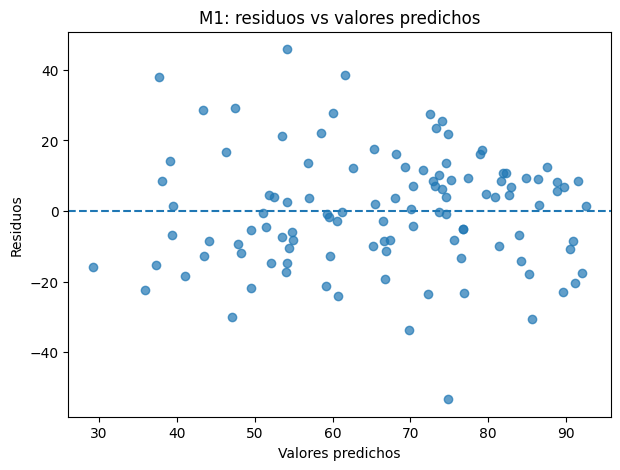

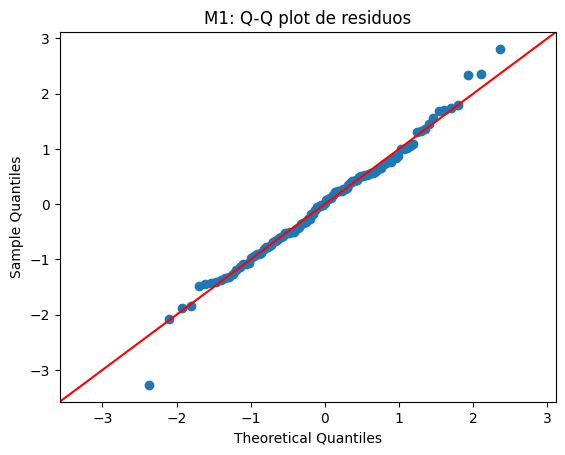

=== NORMALIDAD ===
Shapiro-Wilk: 0.9921
p-value: 0.7746

=== BREUSCH-PAGAN ===
LM statistic: 26.6600
LM p-value:   0.0004
F statistic:  4.6512
F p-value:    0.0001

=== VIF ===


,variable,VIF
0,const,1.000000
1,fatigue,1.266239
2,session,1.171619
3,accuracy,1.969401
4,median_rt,1.667815
5,within_session_rt_change,1.236342
6,within_session_accuracy_change,1.276990


In [31]:
# ============================================================
# DIAGNÓSTICO DEL MODELO M1
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm

from scipy.stats import shapiro
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import variance_inflation_factor


residuals = m1_behavior.resid
fitted = m1_behavior.fittedvalues


# ------------------------------------------------------------
# 1. Residuos vs valores ajustados
# ------------------------------------------------------------

plt.figure(figsize=(7, 5))
plt.scatter(fitted, residuals, alpha=0.7)
plt.axhline(0, linestyle="--")

plt.xlabel("Valores predichos")
plt.ylabel("Residuos")
plt.title("M1: residuos vs valores predichos")

plt.show()


# ------------------------------------------------------------
# 2. Normalidad de residuos
# ------------------------------------------------------------

sm.qqplot(residuals, line="45", fit=True)
plt.title("M1: Q-Q plot de residuos")
plt.show()

shapiro_stat, shapiro_p = shapiro(residuals)

print("=== NORMALIDAD ===")
print(f"Shapiro-Wilk: {shapiro_stat:.4f}")
print(f"p-value: {shapiro_p:.4f}")


# ------------------------------------------------------------
# 3. Heteroscedasticidad
# ------------------------------------------------------------

bp = het_breuschpagan(
    residuals,
    m1_behavior.model.exog
)

print("\n=== BREUSCH-PAGAN ===")
print(f"LM statistic: {bp[0]:.4f}")
print(f"LM p-value:   {bp[1]:.4f}")
print(f"F statistic:  {bp[2]:.4f}")
print(f"F p-value:    {bp[3]:.4f}")


# ------------------------------------------------------------
# 4. Multicolinealidad
# ------------------------------------------------------------

features_vif = [
    "fatigue",
    "session",
    "accuracy",
    "median_rt",
    "within_session_rt_change",
    "within_session_accuracy_change"
]

X_vif = sm.add_constant(
    m1_df[features_vif]
)

vif = pd.DataFrame({
    "variable": X_vif.columns,
    "VIF": [
        variance_inflation_factor(X_vif.values, i)
        for i in range(X_vif.shape[1])
    ]
})

print("\n=== VIF ===")
display(vif)

### Diagnostico de obsevaciones influyentes

=== COOK'S DISTANCE ===
Umbral 4/n: 0.0360
Máximo Cook's D: 0.2006
Observaciones sobre 4/n: 9


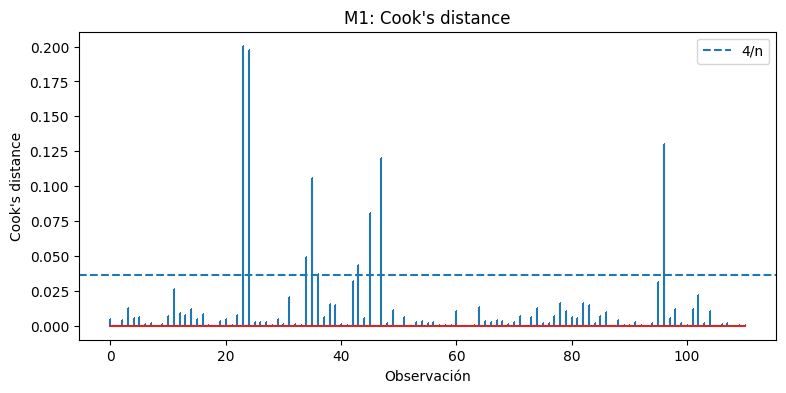

,subject_id,session,condition,fatigue,fatigue_future,accuracy,median_rt,within_session_rt_change,within_session_accuracy_change,fitted,residual,cooks_d
23,14,3,easy,63.321799,35.986159,0.420238,0.586747,-0.021713,-0.033333,69.774601,-33.788442,0.200633
24,14,4,easy,35.986159,100.000000,0.654040,0.578775,-0.015435,-0.065657,54.154155,45.845845,0.197237
105,37,2,hard,53.633218,100.000000,0.652778,0.536150,-0.002499,0.126263,61.540793,38.459207,0.130059
47,23,4,hard,88.235294,55.017301,0.486111,0.479149,-0.020947,-0.080808,85.638380,-30.621079,0.120316
35,18,3,easy,75.778547,21.453287,0.853741,0.491289,-0.007639,0.139456,74.795101,-53.341814,0.105568
45,23,2,hard,46.712803,87.889273,0.818813,0.451352,-0.033080,-0.174242,60.078399,27.810875,0.080576
34,18,2,easy,12.456747,75.778547,0.844697,0.505995,0.016177,0.047980,37.678468,38.100079,0.049368
43,22,3,hard,22.491349,16.955017,0.880708,0.542285,0.029547,-0.102740,47.032086,-30.077068,0.043307
36,18,4,easy,21.453287,71.972318,0.861111,0.478234,0.009591,0.078283,43.419757,28.552561,0.036805


In [32]:
# ============================================================
# OBSERVACIONES INFLUYENTES
# ============================================================

influence = m1_behavior.get_influence()

cooks_d = influence.cooks_distance[0]

threshold = 4 / len(m1_df)

print("=== COOK'S DISTANCE ===")
print(f"Umbral 4/n: {threshold:.4f}")
print(f"Máximo Cook's D: {cooks_d.max():.4f}")
print(
    "Observaciones sobre 4/n:",
    np.sum(cooks_d > threshold)
)


plt.figure(figsize=(9, 4))

plt.stem(
    np.arange(len(cooks_d)),
    cooks_d,
    markerfmt=","
)

plt.axhline(
    threshold,
    linestyle="--",
    label="4/n"
)

plt.xlabel("Observación")
plt.ylabel("Cook's distance")
plt.title("M1: Cook's distance")
plt.legend()

plt.show()


# Identificar observaciones influyentes

influence_df = m1_df.copy()

influence_df["fitted"] = fitted
influence_df["residual"] = residuals
influence_df["cooks_d"] = cooks_d

influential = (
    influence_df[
        influence_df["cooks_d"] > threshold
    ]
    .sort_values(
        "cooks_d",
        ascending=False
    )
)

display(
    influential[
        [
            "subject_id",
            "session",
            "condition",
            "fatigue",
            "fatigue_future",
            "accuracy",
            "median_rt",
            "within_session_rt_change",
            "within_session_accuracy_change",
            "fitted",
            "residual",
            "cooks_d"
        ]
    ]
)

### Análisis de sensibilidad

In [33]:
# ============================================================
# ANÁLISIS DE SENSIBILIDAD
# Exclusión de observaciones con Cook's D > 4/n
# ============================================================

mask_influential = cooks_d > threshold

m1_no_influential_df = (
    m1_df.loc[~mask_influential]
    .copy()
)

print("N análisis principal:", len(m1_df))
print("N análisis sensibilidad:", len(m1_no_influential_df))
print(
    "Sujetos:",
    m1_no_influential_df["subject_id"].nunique()
)

# M0 y M1 en la muestra de sensibilidad

m0_sensitivity = smf.ols(
    """
    fatigue_future ~
        fatigue
        + session
        + C(condition)
    """,
    data=m1_no_influential_df
).fit(
    cov_type="cluster",
    cov_kwds={
        "groups": m1_no_influential_df["subject_id"]
    }
)


m1_sensitivity = smf.ols(
    """
    fatigue_future ~
        fatigue
        + session
        + C(condition)
        + accuracy
        + median_rt
        + within_session_rt_change
        + within_session_accuracy_change
    """,
    data=m1_no_influential_df
).fit(
    cov_type="cluster",
    cov_kwds={
        "groups": m1_no_influential_df["subject_id"]
    }
)

print(m1_sensitivity.summary())

N análisis principal: 111
N análisis sensibilidad: 102
Sujetos: 33
                            OLS Regression Results                            
Dep. Variable:         fatigue_future   R-squared:                       0.658
Model:                            OLS   Adj. R-squared:                  0.632
Method:                 Least Squares   F-statistic:                     30.47
Date:                Sat, 24 Oct 2026   Prob (F-statistic):           2.02e-12
Time:                        11:20:14   Log-Likelihood:                -404.20
No. Observations:                 102   AIC:                             824.4
Df Residuals:                      94   BIC:                             845.4
Df Model:                           7                                         
Covariance Type:              cluster                                         
                                     coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------

### Comparación principal vs sensibilidad

In [34]:
# ============================================================
# COMPARACIÓN DE ROBUSTEZ
# ============================================================

comparison = pd.DataFrame({
    "Análisis": [
        "Principal",
        "Sensibilidad"
    ],

    "N": [
        len(m1_df),
        len(m1_no_influential_df)
    ],

    "M0_R2": [
        m0_matched.rsquared,
        m0_sensitivity.rsquared
    ],

    "M1_R2": [
        m1_behavior.rsquared,
        m1_sensitivity.rsquared
    ],

    "Delta_R2": [
        m1_behavior.rsquared - m0_matched.rsquared,
        m1_sensitivity.rsquared - m0_sensitivity.rsquared
    ],

    "M0_Adj_R2": [
        m0_matched.rsquared_adj,
        m0_sensitivity.rsquared_adj
    ],

    "M1_Adj_R2": [
        m1_behavior.rsquared_adj,
        m1_sensitivity.rsquared_adj
    ],

    "M0_AIC": [
        m0_matched.aic,
        m0_sensitivity.aic
    ],

    "M1_AIC": [
        m1_behavior.aic,
        m1_sensitivity.aic
    ]
})

display(
    comparison.round(4)
)

,Análisis,N,M0_R2,M1_R2,Delta_R2,M0_Adj_R2,M1_Adj_R2,M0_AIC,M1_AIC
0,Principal,111,0.4766,0.4791,0.0025,0.462,0.4437,943.2935,950.7723
1,Sensibilidad,102,0.6545,0.6579,0.0034,0.644,0.6325,817.3960,824.3909


### Random forest principal
Random Forest podía capturar relaciones no lineales e interacciones y M1 igualmente perdió contra M0.

In [35]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GroupKFold
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)

import numpy as np
import pandas as pd


# ============================================================
# FEATURES
# ============================================================

features_m0 = [
    "fatigue",
    "session",
    "condition"
]

features_m1 = [
    "fatigue",
    "session",
    "condition",
    "accuracy",
    "median_rt",
    "within_session_rt_change",
    "within_session_accuracy_change"
]

target = "fatigue_future"
group = "subject_id"


# ============================================================
# PREPARAR DATOS
# ============================================================

rf_df = m1_df[
    list(set(features_m1 + [target, group]))
].dropna().copy()

# Random Forest necesita condition numérica
rf_df["condition_hard"] = (
    rf_df["condition"] == "hard"
).astype(int)

features_m0_rf = [
    "fatigue",
    "session",
    "condition_hard"
]

features_m1_rf = [
    "fatigue",
    "session",
    "condition_hard",
    "accuracy",
    "median_rt",
    "within_session_rt_change",
    "within_session_accuracy_change"
]

print("N:", len(rf_df))
print("Sujetos:", rf_df["subject_id"].nunique())

def evaluate_rf_grouped(df, features):

    X = df[features]
    y = df[target]
    groups = df[group]

    gkf = GroupKFold(n_splits=5)

    fold_results = []
    predictions = np.full(len(df), np.nan)

    for fold, (train_idx, test_idx) in enumerate(
        gkf.split(X, y, groups),
        start=1
    ):

        X_train = X.iloc[train_idx]
        X_test = X.iloc[test_idx]

        y_train = y.iloc[train_idx]
        y_test = y.iloc[test_idx]

        model = RandomForestRegressor(
            n_estimators=500,
            max_features="sqrt",
            min_samples_leaf=3,
            random_state=42,
            n_jobs=-1
        )

        model.fit(X_train, y_train)

        pred = model.predict(X_test)

        predictions[test_idx] = pred

        fold_results.append({
            "fold": fold,
            "R2": r2_score(y_test, pred),
            "MAE": mean_absolute_error(y_test, pred),
            "RMSE": np.sqrt(
                mean_squared_error(y_test, pred)
            )
        })

    results = pd.DataFrame(fold_results)

    # Métricas usando TODAS las predicciones
    # out-of-fold juntas
    overall = {
        "R2": r2_score(y, predictions),
        "MAE": mean_absolute_error(y, predictions),
        "RMSE": np.sqrt(
            mean_squared_error(y, predictions)
        )
    }

    return results, overall, predictions


# ============================================================
# RANDOM FOREST M0
# ============================================================

rf_m0_folds, rf_m0, pred_m0 = evaluate_rf_grouped(
    rf_df,
    features_m0_rf
)


# ============================================================
# RANDOM FOREST M1
# ============================================================

rf_m1_folds, rf_m1, pred_m1 = evaluate_rf_grouped(
    rf_df,
    features_m1_rf
)

print("=== RANDOM FOREST M0 ===")
display(rf_m0_folds.round(3))

print("Overall OOF:")
print(rf_m0)


print("\n=== RANDOM FOREST M1 ===")
display(rf_m1_folds.round(3))

print("Overall OOF:")
print(rf_m1)

N: 111
Sujetos: 34
=== RANDOM FOREST M0 ===


,fold,R2,MAE,RMSE
0,1,0.515,12.774,16.384
1,2,0.337,15.368,18.988
2,3,0.274,17.194,20.834
3,4,0.151,11.515,14.674
4,5,0.424,11.315,14.358


Overall OOF:
{'R2': 0.4187144521668348, 'MAE': 13.630530339751944, 'RMSE': np.float64(17.2287711118058)}

=== RANDOM FOREST M1 ===


,fold,R2,MAE,RMSE
0,1,0.458,13.201,17.308
1,2,0.178,17.407,21.141
2,3,0.261,17.166,21.025
3,4,0.143,11.262,14.744
4,5,0.392,12.961,14.751


Overall OOF:
{'R2': 0.3661020463877569, 'MAE': 14.369021156606536, 'RMSE': np.float64(17.991576238901473)}


### Random forest sensibilidad

In [36]:
# ============================================================
# RANDOM FOREST — SENSITIVITY ANALYSIS
# ============================================================

rf_sensitivity_df = (
    m1_no_influential_df.copy()
)

rf_sensitivity_df["condition_hard"] = (
    rf_sensitivity_df["condition"] == "hard"
).astype(int)


rf_sens_m0_folds, rf_sens_m0, pred_sens_m0 = (
    evaluate_rf_grouped(
        rf_sensitivity_df,
        features_m0_rf
    )
)

rf_sens_m1_folds, rf_sens_m1, pred_sens_m1 = (
    evaluate_rf_grouped(
        rf_sensitivity_df,
        features_m1_rf
    )
)


comparison_rf_sensitivity = pd.DataFrame({
    "Model": [
        "RF M0 - Global",
        "RF M1 - Global",
        "RF M0 - Sensitivity",
        "RF M1 - Sensitivity"
    ],

    "R2_OOF": [
        rf_m0["R2"],
        rf_m1["R2"],
        rf_sens_m0["R2"],
        rf_sens_m1["R2"]
    ],

    "MAE_OOF": [
        rf_m0["MAE"],
        rf_m1["MAE"],
        rf_sens_m0["MAE"],
        rf_sens_m1["MAE"]
    ],

    "RMSE_OOF": [
        rf_m0["RMSE"],
        rf_m1["RMSE"],
        rf_sens_m0["RMSE"],
        rf_sens_m1["RMSE"]
    ]
})

display(
    comparison_rf_sensitivity.round(4)
)

,Model,R2_OOF,MAE_OOF,RMSE_OOF
0,RF M0 - Global,0.4187,13.6305,17.2288
1,RF M1 - Global,0.3661,14.3690,17.9916
2,RF M0 - Sensitivity,0.5626,11.8936,14.3924
3,RF M1 - Sensitivity,0.5246,12.3295,15.0042


La fatiga actual contiene una señal predictiva considerable sobre la fatiga futura. Las medidas conductuales seleccionadas no aportan valor predictivo incremental y, en modelos no lineales evaluados fuera de muestra, incluso reducen el rendimiento.

Una pequeña cantidad de transiciones altamente influyentes explica además una parte sustancial del error de predicción del modelo global.

La fatiga futura es moderadamente predecible bajo transiciones típicas, pero existen transiciones abruptas que reducen sustancialmente la predictibilidad.

# Más análisis, ahora con M2 y M3

### M2: M0 + Glu_tCr, ¿el glutamato añade infomación predictiva?

In [37]:
print("glu:")
print(glu.shape)
print(glu.columns.tolist())

print("\nglu_wide:")
print(glu_wide.shape)
print(glu_wide.columns.tolist())

print(model_full.columns.tolist())

glu:
(194, 10)
['subject_id', 'Linewidth', 'SNR', 'WCONC_corr', 'ROI', 'session', 'condition', 'distance', 'rotation', 'Glu_tCr']

glu_wide:
(111, 15)
['subject_id', 'condition', 'session', 'MRS_Glu_tCr_PFC', 'MRS_Glu_tCr_VC', 'MRS_Linewidth_PFC', 'MRS_Linewidth_VC', 'MRS_SNR_PFC', 'MRS_SNR_VC', 'MRS_WCONC_corr_PFC', 'MRS_WCONC_corr_VC', 'MRS_distance_PFC', 'MRS_distance_VC', 'MRS_rotation_PFC', 'MRS_rotation_VC']
['subject_id', 'condition', 'session', 'fatigue', 'fatigue_future', 'session_future', 'session_gap', 'delta_fatigue', 'n_trials', 'accuracy', 'mean_rt', 'median_rt', 'rt_std', 'switch_fraction', 'early_accuracy', 'early_rt', 'late_accuracy', 'late_rt', 'within_session_rt_change', 'within_session_accuracy_change', 'DWS_ADC_log_Glu_Gln_lin_PFC', 'DWS_ADC_log_Glu_Gln_lin_VC', 'DWS_WCONC_corr_PFC', 'DWS_WCONC_corr_VC', 'DWS_p_shots_kept_PFC', 'DWS_p_shots_kept_VC', 'DWS_SN_PFC', 'DWS_SN_VC', 'DWS_linewidth_PFC', 'DWS_linewidth_VC', 'MRS_Glu_tCr_PFC', 'MRS_Glu_tCr_VC', 'MRS_Linewi

In [38]:
import statsmodels.formula.api as smf
import pandas as pd

# ============================================================
# MUESTRA COMÚN M0 / M1 / M2
# ============================================================

common_vars = [
    "subject_id",
    "fatigue_future",
    "fatigue",
    "session",
    "condition",

    # M1: comportamiento
    "accuracy",
    "median_rt",
    "within_session_rt_change",
    "within_session_accuracy_change",

    # M2: glutamato PFC
    "MRS_Glu_tCr_PFC"
]

m2_comparison_df = (
    model_full[common_vars]
    .dropna()
    .copy()
)

print("=== MUESTRA COMÚN ===")
print(f"N observaciones: {len(m2_comparison_df)}")
print(f"N sujetos:       {m2_comparison_df['subject_id'].nunique()}")
print(
    "Sesiones:",
    sorted(m2_comparison_df["session"].unique())
)


# ============================================================
# M0 — BASELINE
# ============================================================

m0_glu_matched = smf.ols(
    """
    fatigue_future ~
        fatigue
        + session
        + C(condition)
    """,
    data=m2_comparison_df
).fit(
    cov_type="cluster",
    cov_kwds={"groups": m2_comparison_df["subject_id"]}
)


# ============================================================
# M1 — BEHAVIOR
# ============================================================

m1_glu_matched = smf.ols(
    """
    fatigue_future ~
        fatigue
        + session
        + C(condition)
        + accuracy
        + median_rt
        + within_session_rt_change
        + within_session_accuracy_change
    """,
    data=m2_comparison_df
).fit(
    cov_type="cluster",
    cov_kwds={"groups": m2_comparison_df["subject_id"]}
)


# ============================================================
# M2 — GLUTAMATE
# ============================================================

m2_glutamate = smf.ols(
    """
    fatigue_future ~
        fatigue
        + session
        + C(condition)
        + MRS_Glu_tCr_PFC
    """,
    data=m2_comparison_df
).fit(
    cov_type="cluster",
    cov_kwds={"groups": m2_comparison_df["subject_id"]}
)


# ============================================================
# RESUMEN M2
# ============================================================

print("\n" + "=" * 70)
print("M2 — GLUTAMATE MODEL")
print("=" * 70)

print(m2_glutamate.summary())


# ============================================================
# TABLA COMPARATIVA
# ============================================================

comparison_m012 = pd.DataFrame({
    "Model": [
        "M0 — Baseline",
        "M1 — Behavior",
        "M2 — Glutamate"
    ],

    "R2": [
        m0_glu_matched.rsquared,
        m1_glu_matched.rsquared,
        m2_glutamate.rsquared
    ],

    "Adjusted_R2": [
        m0_glu_matched.rsquared_adj,
        m1_glu_matched.rsquared_adj,
        m2_glutamate.rsquared_adj
    ],

    "AIC": [
        m0_glu_matched.aic,
        m1_glu_matched.aic,
        m2_glutamate.aic
    ],

    "BIC": [
        m0_glu_matched.bic,
        m1_glu_matched.bic,
        m2_glutamate.bic
    ]
})

comparison_m012["Delta_R2_vs_M0"] = (
    comparison_m012["R2"]
    - m0_glu_matched.rsquared
)

print("\n" + "=" * 70)
print("COMPARACIÓN M0 vs M1 vs M2")
print("=" * 70)

print("\n" + "=" * 70)
print("COMPARACIÓN M0 vs M1 vs M2")
print("=" * 70)

print(f"{'Modelo':<22} {'R²':>8} {'Adj. R²':>10} {'ΔR² vs M0':>12} {'AIC':>10} {'BIC':>10}")
print("-" * 75)

print(
    f"{'M0 — Baseline':<22} "
    f"{m0_glu_matched.rsquared:>8.4f} "
    f"{m0_glu_matched.rsquared_adj:>10.4f} "
    f"{0:>12.4f} "
    f"{m0_glu_matched.aic:>10.2f} "
    f"{m0_glu_matched.bic:>10.2f}"
)

print(
    f"{'M1 — Behavior':<22} "
    f"{m1_glu_matched.rsquared:>8.4f} "
    f"{m1_glu_matched.rsquared_adj:>10.4f} "
    f"{m1_glu_matched.rsquared - m0_glu_matched.rsquared:>12.4f} "
    f"{m1_glu_matched.aic:>10.2f} "
    f"{m1_glu_matched.bic:>10.2f}"
)

print(
    f"{'M2 — Glutamate':<22} "
    f"{m2_glutamate.rsquared:>8.4f} "
    f"{m2_glutamate.rsquared_adj:>10.4f} "
    f"{m2_glutamate.rsquared - m0_glu_matched.rsquared:>12.4f} "
    f"{m2_glutamate.aic:>10.2f} "
    f"{m2_glutamate.bic:>10.2f}"
)

=== MUESTRA COMÚN ===
N observaciones: 36
N sujetos:       28
Sesiones: [np.int64(1), np.int64(3)]

M2 — GLUTAMATE MODEL
                            OLS Regression Results                            
Dep. Variable:         fatigue_future   R-squared:                       0.633
Model:                            OLS   Adj. R-squared:                  0.586
Method:                 Least Squares   F-statistic:                     19.72
Date:                Sat, 24 Oct 2026   Prob (F-statistic):           1.08e-07
Time:                        11:20:46   Log-Likelihood:                -146.44
No. Observations:                  36   AIC:                             302.9
Df Residuals:                      31   BIC:                             310.8
Df Model:                           4                                         
Covariance Type:              cluster                                         
                           coef    std err          z      P>|z|      [0.025      0.975]


### M0 vs M1 vs M2 con predicciones OOF y GroupKFold por subject_id

In [39]:
# ============================================================
# OOF: M0 vs M1 vs M2
# GroupKFold por subject_id
# Misma muestra MRS (N = 36)
# ============================================================

import numpy as np
import pandas as pd

from sklearn.model_selection import GroupKFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)


# ============================================================
# 1. MUESTRA COMÚN
# ============================================================

features_m0 = [
    "fatigue",
    "session",
    "condition"
]

features_m1 = [
    "fatigue",
    "session",
    "condition",
    "accuracy",
    "median_rt",
    "within_session_rt_change",
    "within_session_accuracy_change"
]

features_m2 = [
    "fatigue",
    "session",
    "condition",
    "MRS_Glu_tCr_PFC"
]

all_required = list(set(
    ["subject_id", "fatigue_future"]
    + features_m0
    + features_m1
    + features_m2
))

oof_df = (
    model_full[all_required]
    .dropna()
    .copy()
    .reset_index(drop=True)
)

print("=== MUESTRA OOF ===")
print("N observaciones:", len(oof_df))
print("N sujetos:", oof_df["subject_id"].nunique())
print("Sesiones:", sorted(oof_df["session"].unique()))


# ============================================================
# 2. FUNCIÓN PARA CREAR MODELO
# ============================================================

def make_model(features):

    categorical = [
        col for col in features
        if col == "condition"
    ]

    numeric = [
        col for col in features
        if col not in categorical
    ]

    preprocessor = ColumnTransformer(
        transformers=[
            (
                "num",
                StandardScaler(),
                numeric
            ),
            (
                "cat",
                OneHotEncoder(
                    drop="first",
                    handle_unknown="ignore"
                ),
                categorical
            )
        ]
    )

    model = Pipeline([
        ("preprocessor", preprocessor),
        ("regression", LinearRegression())
    ])

    return model


# ============================================================
# 3. FUNCIÓN OOF CON GROUPKFOLD
# ============================================================

def evaluate_oof(df, features, n_splits=5):

    X = df[features]
    y = df["fatigue_future"].to_numpy()
    groups = df["subject_id"].to_numpy()

    gkf = GroupKFold(n_splits=n_splits)

    predictions = np.full(len(df), np.nan)

    fold_results = []

    for fold, (train_idx, test_idx) in enumerate(
        gkf.split(X, y, groups),
        start=1
    ):

        model = make_model(features)

        X_train = X.iloc[train_idx]
        X_test = X.iloc[test_idx]

        y_train = y[train_idx]
        y_test = y[test_idx]

        model.fit(X_train, y_train)

        pred = model.predict(X_test)

        predictions[test_idx] = pred

        # Métricas por fold
        mae = mean_absolute_error(y_test, pred)

        rmse = np.sqrt(
            mean_squared_error(y_test, pred)
        )

        # R² solo si hay suficientes observaciones
        if len(y_test) > 1:
            r2 = r2_score(y_test, pred)
        else:
            r2 = np.nan

        fold_results.append({
            "fold": fold,
            "n_test": len(test_idx),
            "n_subjects_test": len(
                np.unique(groups[test_idx])
            ),
            "R2": r2,
            "MAE": mae,
            "RMSE": rmse
        })


    # ========================================================
    # MÉTRICAS OOF GLOBALES
    # ========================================================

    r2_oof = r2_score(
        y,
        predictions
    )

    mae_oof = mean_absolute_error(
        y,
        predictions
    )

    rmse_oof = np.sqrt(
        mean_squared_error(
            y,
            predictions
        )
    )

    return {
        "R2_OOF": r2_oof,
        "MAE_OOF": mae_oof,
        "RMSE_OOF": rmse_oof,
        "predictions": predictions,
        "fold_results": pd.DataFrame(fold_results)
    }


# ============================================================
# 4. EVALUAR LOS TRES MODELOS
# ============================================================

result_m0 = evaluate_oof(
    oof_df,
    features_m0
)

result_m1 = evaluate_oof(
    oof_df,
    features_m1
)

result_m2 = evaluate_oof(
    oof_df,
    features_m2
)


# ============================================================
# 5. TABLA FINAL
# ============================================================

comparison_oof = pd.DataFrame({

    "Model": [
        "M0 — Baseline",
        "M1 — Behavior",
        "M2 — Glutamate"
    ],

    "R2_OOF": [
        result_m0["R2_OOF"],
        result_m1["R2_OOF"],
        result_m2["R2_OOF"]
    ],

    "MAE_OOF": [
        result_m0["MAE_OOF"],
        result_m1["MAE_OOF"],
        result_m2["MAE_OOF"]
    ],

    "RMSE_OOF": [
        result_m0["RMSE_OOF"],
        result_m1["RMSE_OOF"],
        result_m2["RMSE_OOF"]
    ]
})


# Incremento respecto a M0
comparison_oof["Delta_R2_vs_M0"] = (
    comparison_oof["R2_OOF"]
    - result_m0["R2_OOF"]
)


print("\n" + "=" * 70)
print("RESULTADOS OOF — GROUPKFOLD POR SUJETO")
print("=" * 70)

print(
    comparison_oof
    .round(4)
    .to_string(index=False)
)

=== MUESTRA OOF ===
N observaciones: 36
N sujetos: 28
Sesiones: [np.int64(1), np.int64(3)]

RESULTADOS OOF — GROUPKFOLD POR SUJETO
         Model  R2_OOF  MAE_OOF  RMSE_OOF  Delta_R2_vs_M0
 M0 — Baseline  0.5155  12.6244   16.2547          0.0000
 M1 — Behavior  0.4729  13.0087   16.9538         -0.0426
M2 — Glutamate  0.5267  13.0213   16.0646          0.0113


### M3: M0 + conducta + Glutamato

In [40]:
# ============================================================
# M3 — BEHAVIOR + GLUTAMATE
# ============================================================

features_m3 = [
    # M0
    "fatigue",
    "session",
    "condition",

    # Behavior
    "accuracy",
    "median_rt",
    "within_session_rt_change",
    "within_session_accuracy_change",

    # Glutamate
    "MRS_Glu_tCr_PFC"
]


# ============================================================
# Evaluación OOF
# ============================================================

result_m3 = evaluate_oof(
    oof_df,
    features_m3
)


# ============================================================
# Comparación M0 / M1 / M2 / M3
# ============================================================

comparison_oof_m3 = pd.DataFrame({

    "Model": [
        "M0 — Baseline",
        "M1 — Behavior",
        "M2 — Glutamate",
        "M3 — Behavior + Glutamate"
    ],

    "R2_OOF": [
        result_m0["R2_OOF"],
        result_m1["R2_OOF"],
        result_m2["R2_OOF"],
        result_m3["R2_OOF"]
    ],

    "MAE_OOF": [
        result_m0["MAE_OOF"],
        result_m1["MAE_OOF"],
        result_m2["MAE_OOF"],
        result_m3["MAE_OOF"]
    ],

    "RMSE_OOF": [
        result_m0["RMSE_OOF"],
        result_m1["RMSE_OOF"],
        result_m2["RMSE_OOF"],
        result_m3["RMSE_OOF"]
    ]
})


comparison_oof_m3["Delta_R2_vs_M0"] = (
    comparison_oof_m3["R2_OOF"]
    - result_m0["R2_OOF"]
)


print("\n" + "=" * 80)
print("RESULTADOS OOF — M0 vs M1 vs M2 vs M3")
print("=" * 80)

print(
    comparison_oof_m3
    .round(4)
    .to_string(index=False)
)


RESULTADOS OOF — M0 vs M1 vs M2 vs M3
                    Model  R2_OOF  MAE_OOF  RMSE_OOF  Delta_R2_vs_M0
            M0 — Baseline  0.5155  12.6244   16.2547          0.0000
            M1 — Behavior  0.4729  13.0087   16.9538         -0.0426
           M2 — Glutamate  0.5267  13.0213   16.0646          0.0113
M3 — Behavior + Glutamate  0.4455  13.0317   17.3886         -0.0700


Future fatigue was substantially predictable from current fatigue and basic experimental covariates. Neither behavioral measures nor their combination with prefrontal glutamate provided incremental out-of-sample predictive value. Glutamate alone produced only a marginal and metric-dependent improvement.

### Random forest M0, M1, M2 y M3

In [41]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GroupKFold
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)

import numpy as np
import pandas as pd


# ============================================================
# RANDOM FOREST OOF
# GroupKFold por subject_id
# ============================================================

def evaluate_rf_oof(
    df,
    features,
    n_splits=5,
    random_state=42
):

    X = df[features].copy()
    y = df["fatigue_future"].to_numpy()
    groups = df["subject_id"].to_numpy()

    # Convertir condition a dummy
    X = pd.get_dummies(
        X,
        columns=["condition"],
        drop_first=True
    )

    gkf = GroupKFold(n_splits=n_splits)

    predictions = np.full(len(df), np.nan)

    fold_results = []

    for fold, (train_idx, test_idx) in enumerate(
        gkf.split(X, y, groups),
        start=1
    ):

        X_train = X.iloc[train_idx]
        X_test = X.iloc[test_idx]

        y_train = y[train_idx]
        y_test = y[test_idx]

        # MISMO RF PARA TODOS LOS MODELOS
        rf = RandomForestRegressor(
            n_estimators=500,
            max_features="sqrt",
            min_samples_leaf=2,
            random_state=random_state,
            n_jobs=-1
        )

        rf.fit(X_train, y_train)

        pred = rf.predict(X_test)

        predictions[test_idx] = pred

        fold_results.append({
            "fold": fold,
            "MAE": mean_absolute_error(
                y_test,
                pred
            ),
            "RMSE": np.sqrt(
                mean_squared_error(
                    y_test,
                    pred
                )
            )
        })


    # ========================================================
    # MÉTRICAS OOF GLOBALES
    # ========================================================

    r2 = r2_score(
        y,
        predictions
    )

    mae = mean_absolute_error(
        y,
        predictions
    )

    rmse = np.sqrt(
        mean_squared_error(
            y,
            predictions
        )
    )

    return {
        "R2_OOF": r2,
        "MAE_OOF": mae,
        "RMSE_OOF": rmse,
        "predictions": predictions,
        "fold_results": pd.DataFrame(fold_results)
    }


# ============================================================
# EVALUAR M0–M3
# ============================================================

rf_m0 = evaluate_rf_oof(
    oof_df,
    features_m0
)

rf_m1 = evaluate_rf_oof(
    oof_df,
    features_m1
)

rf_m2 = evaluate_rf_oof(
    oof_df,
    features_m2
)

rf_m3 = evaluate_rf_oof(
    oof_df,
    features_m3
)


# ============================================================
# TABLA COMPARATIVA
# ============================================================

rf_comparison_m0123 = pd.DataFrame({

    "Model": [
        "RF M0 — Baseline",
        "RF M1 — Behavior",
        "RF M2 — Glutamate",
        "RF M3 — Behavior + Glutamate"
    ],

    "R2_OOF": [
        rf_m0["R2_OOF"],
        rf_m1["R2_OOF"],
        rf_m2["R2_OOF"],
        rf_m3["R2_OOF"]
    ],

    "MAE_OOF": [
        rf_m0["MAE_OOF"],
        rf_m1["MAE_OOF"],
        rf_m2["MAE_OOF"],
        rf_m3["MAE_OOF"]
    ],

    "RMSE_OOF": [
        rf_m0["RMSE_OOF"],
        rf_m1["RMSE_OOF"],
        rf_m2["RMSE_OOF"],
        rf_m3["RMSE_OOF"]
    ]
})


rf_comparison_m0123["Delta_R2_vs_M0"] = (
    rf_comparison_m0123["R2_OOF"]
    - rf_m0["R2_OOF"]
)


print("\n" + "=" * 85)
print("RANDOM FOREST — OOF GROUPKFOLD POR SUJETO")
print("=" * 85)

print(
    rf_comparison_m0123
    .round(4)
    .to_string(index=False)
)


RANDOM FOREST — OOF GROUPKFOLD POR SUJETO
                       Model  R2_OOF  MAE_OOF  RMSE_OOF  Delta_R2_vs_M0
            RF M0 — Baseline  0.5199  13.0590   16.1799          0.0000
            RF M1 — Behavior  0.3063  15.5065   19.4494         -0.2136
           RF M2 — Glutamate  0.5573  12.8094   15.5370          0.0374
RF M3 — Behavior + Glutamate  0.3304  15.2677   19.1082         -0.1895


### Prueba de estabilidad: ¿la ventaja de M2 sobre M0 aparece consistentemente cuando cambiamos qué sujetos quedan fuera?

In [42]:
# ============================================================
# ESTABILIDAD RF: M0 vs M2
# Repeated GroupShuffleSplit
# ============================================================

import numpy as np
import pandas as pd

from sklearn.model_selection import GroupShuffleSplit
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)


# ============================================================
# 1. PREPARAR DATOS
# ============================================================

features_m0_rf = [
    "fatigue",
    "session",
    "condition"
]

features_m2_rf = [
    "fatigue",
    "session",
    "condition",
    "MRS_Glu_tCr_PFC"
]

stability_df = oof_df.copy()

y = stability_df["fatigue_future"].to_numpy()
groups = stability_df["subject_id"].to_numpy()


# Convertimos condition a dummy por separado
X_m0 = pd.get_dummies(
    stability_df[features_m0_rf],
    columns=["condition"],
    drop_first=True
)

X_m2 = pd.get_dummies(
    stability_df[features_m2_rf],
    columns=["condition"],
    drop_first=True
)


# ============================================================
# 2. SPLITS REPETIDOS POR SUJETO
# ============================================================

N_REPEATS = 50

splitter = GroupShuffleSplit(
    n_splits=N_REPEATS,
    test_size=0.25,
    random_state=42
)

results = []

for repeat, (train_idx, test_idx) in enumerate(
    splitter.split(X_m0, y, groups),
    start=1
):

    y_train = y[train_idx]
    y_test = y[test_idx]

    rf_m0_rep = RandomForestRegressor(
        n_estimators=100,
        max_features="sqrt",
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    )

    rf_m2_rep = RandomForestRegressor(
        n_estimators=100,
        max_features="sqrt",
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    )

    rf_m0_rep.fit(
        X_m0.iloc[train_idx],
        y_train
    )

    rf_m2_rep.fit(
        X_m2.iloc[train_idx],
        y_train
    )

    pred_m0 = rf_m0_rep.predict(
        X_m0.iloc[test_idx]
    )

    pred_m2 = rf_m2_rep.predict(
        X_m2.iloc[test_idx]
    )

    r2_m0 = r2_score(y_test, pred_m0)
    r2_m2 = r2_score(y_test, pred_m2)

    mae_m0 = mean_absolute_error(
        y_test,
        pred_m0
    )

    mae_m2 = mean_absolute_error(
        y_test,
        pred_m2
    )

    rmse_m0 = np.sqrt(
        mean_squared_error(
            y_test,
            pred_m0
        )
    )

    rmse_m2 = np.sqrt(
        mean_squared_error(
            y_test,
            pred_m2
        )
    )

    results.append({
        "repeat": repeat,
        "R2_M0": r2_m0,
        "R2_M2": r2_m2,
        "Delta_R2": r2_m2 - r2_m0,
        "MAE_M0": mae_m0,
        "MAE_M2": mae_m2,
        "Delta_MAE": mae_m0 - mae_m2,
        "RMSE_M0": rmse_m0,
        "RMSE_M2": rmse_m2,
        "Delta_RMSE": rmse_m0 - rmse_m2
    })

stability_results = pd.DataFrame(results)

In [43]:
# ============================================================
# 4. RESUMEN DE ESTABILIDAD
# ============================================================

print("=" * 70)
print("ESTABILIDAD RF — M0 vs M2")
print("=" * 70)

print(f"\nRepeticiones: {len(stability_results)}")

print("\n--- ΔR² (M2 - M0) ---")

print(
    f"Media:    "
    f"{stability_results['Delta_R2'].mean():.4f}"
)

print(
    f"Mediana:  "
    f"{stability_results['Delta_R2'].median():.4f}"
)

print(
    f"SD:       "
    f"{stability_results['Delta_R2'].std():.4f}"
)

print(
    f"Q2.5%:    "
    f"{stability_results['Delta_R2'].quantile(.025):.4f}"
)

print(
    f"Q97.5%:   "
    f"{stability_results['Delta_R2'].quantile(.975):.4f}"
)


# ============================================================
# 5. ¿CON QUÉ FRECUENCIA GANA M2?
# ============================================================

p_r2 = (
    stability_results["Delta_R2"] > 0
).mean()

p_mae = (
    stability_results["Delta_MAE"] > 0
).mean()

p_rmse = (
    stability_results["Delta_RMSE"] > 0
).mean()


print("\n--- FRECUENCIA EN QUE M2 SUPERA A M0 ---")

print(
    f"Mayor R²:   {p_r2:.1%}"
)

print(
    f"Menor MAE:  {p_mae:.1%}"
)

print(
    f"Menor RMSE: {p_rmse:.1%}"
)


# ============================================================
# 6. RESULTADOS EXTREMOS
# ============================================================

print("\n--- RANGO ΔR² ---")

print(
    f"Mínimo: {stability_results['Delta_R2'].min():.4f}"
)

print(
    f"Máximo: {stability_results['Delta_R2'].max():.4f}"
)

ESTABILIDAD RF — M0 vs M2

Repeticiones: 50

--- ΔR² (M2 - M0) ---
Media:    0.0786
Mediana:  0.0776
SD:       0.1486
Q2.5%:    -0.1860
Q97.5%:   0.4130

--- FRECUENCIA EN QUE M2 SUPERA A M0 ---
Mayor R²:   78.0%
Menor MAE:  68.0%
Menor RMSE: 78.0%

--- RANGO ΔR² ---
Mínimo: -0.3755
Máximo: 0.4224


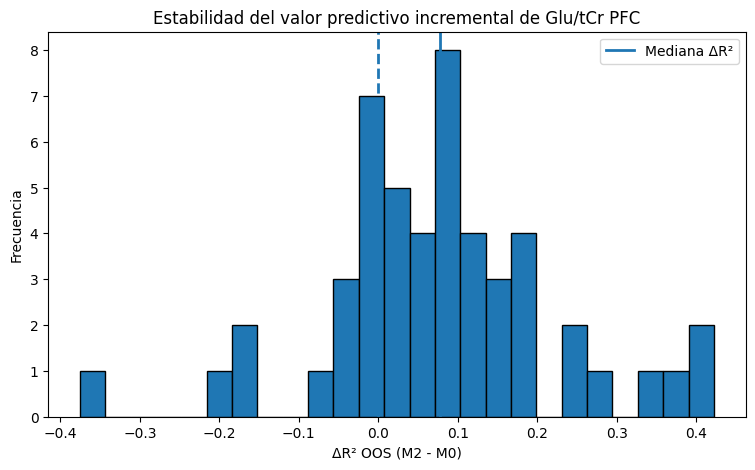

In [44]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.hist(
    stability_results["Delta_R2"],
    bins=25,
    edgecolor="black"
)

plt.axvline(
    0,
    linestyle="--",
    linewidth=2
)

plt.axvline(
    stability_results["Delta_R2"].median(),
    linestyle="-",
    linewidth=2,
    label="Mediana ΔR²"
)

plt.xlabel("ΔR² OOS (M2 - M0)")
plt.ylabel("Frecuencia")
plt.title(
    "Estabilidad del valor predictivo incremental de Glu/tCr PFC"
)

plt.legend()
plt.show()

Exploratory analyses suggested potential incremental predictive value of PFC Glu/tCr. Across repeated subject-wise train-test splits, the glutamate-augmented model outperformed the baseline model in out-of-sample \(R^2\) in 78% of partitions (median \(\Delta R^2=0.078\)). However, performance differences were highly variable across partitions, consistent with substantial uncertainty arising from the small MRS subsample (36 observations from 28 participants).

# ¿qué chucha está ocurriendo en esas transiciones que el modelo no sabe predecir?